1. What is Probability
2. Frequency Table - One way frequency - Two way frequency table
3. Random Variable
4. Expected Value
5. Independent and dependent variable

Statistics 

1. Understanding the number (probability / Distributions
2. Present your findings

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>Import the libraries </h3>
</div>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>Variables for Plotting </h3>
</div>

In [ ]:
# One consistent, calm plotting style for the whole lecture
BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#0b0b0b"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
})
rng = np.random.default_rng(42)     # fixed seed, so every student gets the same "random" results

In [ ]:
tips = sns.load_dataset("tips")

tips.head()

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> Discrete vs continuous </h3>
</div>

# Describing Data with Distributions: PMF, PDF, CDF & ECDF
### Using the `tips` dataset from Seaborn

**Where this fits:** You already know what **continuous** and **discrete** variables are. This notebook shows how to **draw** how their values are spread, and how to **describe** what you see.

**By the end you will be able to:**
1. Tell discrete and continuous variables apart, and know how each is represented
2. Choose the right plot: **PMF, PDF, CDF or ECDF**
3. Draw each one in Python and **describe it in plain English**

| Section | Plot | Variable used |
|:---:|:---|:---|
| 1 | Discrete vs Continuous | all columns |
| 2 | PMF vs PDF vs CDF vs ECDF | overview |
| 3 | **PMF** | `size` (discrete) |
| 4 | **PDF** | `total_bill` (continuous) |
| 5 | **CDF** | `tip` (continuous) |
| 6 | **ECDF** | `size` (discrete) |

## 0. Setup
Run this cell first. It loads the libraries and the data and sets a clean plot style.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# A clean, consistent look for every chart in this notebook
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#6b6b6b"

tips = sns.load_dataset("tips")
print("Rows:", len(tips))
tips.head()

Rows: 244


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


---
## 1. Discrete vs Continuous Variables

| | **Discrete variable** | **Continuous variable** |
|---|---|---|
| **(a) What it is** | A value you **count**. It can only take separate, fixed values (usually whole numbers), with gaps in between. | A value you **measure**. It can take **any** value in a range, including decimals. |
| **Quick test** | *"Can I have 2.5 of it?"* **No** | *"Can I have 2.5 of it?"* **Yes** |
| **(b) How it's represented** | **Bar chart / PMF**: a separate bar for each value, with gaps. **ECDF**: a staircase of steps. | **Histogram** (touching bars over ranges), **PDF**: a smooth curve. **CDF**: a smooth rising curve. |
| **Probability question** | *"What's the chance of **exactly** 2?"* makes sense. | *"What's the chance of **exactly** \$17.2300…?"* is essentially **0**, so we ask about **ranges** (e.g. \$10–\$20). |
| **(c) Examples: everyday** | Number of students in a class, goals in a match, cars in a car park, dice roll | Height, weight, temperature, time to finish a race |
| **(c) Examples: tips dataset** | `size` (people at the table: 1, 2, 3…6) | `total_bill`, `tip` (any dollar amount) |

> **Note:** `sex`, `smoker`, `day` and `time` are **categorical** (labels, not numbers), so they are neither discrete nor continuous in this sense.

Let's classify every column in the dataset:

In [2]:
summary = pd.DataFrame({
    "Column":        ["total_bill", "tip", "size", "sex", "smoker", "day", "time"],
    "Type":          ["Continuous", "Continuous", "Discrete", "Categorical", "Categorical", "Categorical", "Categorical"],
    "Why":           ["Money: any amount, e.g. 16.99", "Money: any amount, e.g. 1.01",
                      "People: counted, 1 to 6", "Label", "Label", "Label", "Label"],
    "Unique values": [tips[c].nunique() for c in ["total_bill", "tip", "size", "sex", "smoker", "day", "time"]],
})
summary

,Column,Type,Why,Unique values
0,total_bill,Continuous,"Money: any amount, e.g. 16.99",229
1,tip,Continuous,"Money: any amount, e.g. 1.01",123
2,size,Discrete,"People: counted, 1 to 6",6
3,sex,Categorical,Label,2
4,smoker,Categorical,Label,2
5,day,Categorical,Label,4
6,time,Categorical,Label,2


**Look at the `Unique values` column:** `size` has only **6** possible values, but `total_bill` has **229** different values in 244 rows. That's a strong clue that one is discrete and the other continuous.

### Seeing the difference

In [3]:
tips.head(2)

tips.groupby('size')['size'].count()

size
1      4
2    156
3     38
4     37
5      5
6      4
Name: size, dtype: int64

In [ ]:
DISCRETE VARIABLE
-----------------
- Individual chances/Probability - PMF
- Cumulative Values - ECDF

Continuous Variable 
---------------------

- Individual Probability - PDF
- Cumulative Probability - CDF

---
## 2. PMF vs PDF vs CDF vs ECDF

| | **PMF**<br>Probability *Mass* Function | **PDF**<br>Probability *Density* Function | **CDF**<br>Cumulative Distribution Function | **ECDF**<br>*Empirical* CDF |
|---|---|---|---|---|
| **Used for** | Discrete | Continuous | continuous) |  discrete) |
| **Question it answers** | *"Chance of **exactly** x?"* | *"Where are the values **concentrated**?"* | *"Chance of **x or less**?"* | *"What **fraction of my data** is x or less?"* |
| **What the height means** | A probability | **Not** a probability. Only the **area** under the curve is. | A probability (0 to 1) | A proportion (0 to 1) |
| **Looks like** | Separate bars / lollipops | Smooth hill-shaped curve | Smooth S-shaped curve rising to 1 | Staircase rising to 1 |
| **Adds up to** | All bars add to **1** | Total **area** = 1 | Ends at **1** | Ends at **1** |
| **Built from** | Counts ÷ total | A smoothed estimate (KDE) | Running total of the PDF | Directly from the data, no smoothing |
| **Seaborn** | `histplot(stat="probability", discrete=True)` | `kdeplot()` | `kdeplot(cumulative=True)` | `ecdfplot()` |
| **Tips example** | `size` | `total_bill` | `tip` | `size` |

**How they connect:**
- **PMF / PDF** show *how much is at each value* (the **shape**).
- **CDF / ECDF** show *how much has piled up so far* (the **running total**).
- Add up PMF bars left to right and you get the ECDF steps. Add up the area under the PDF and you get the CDF.

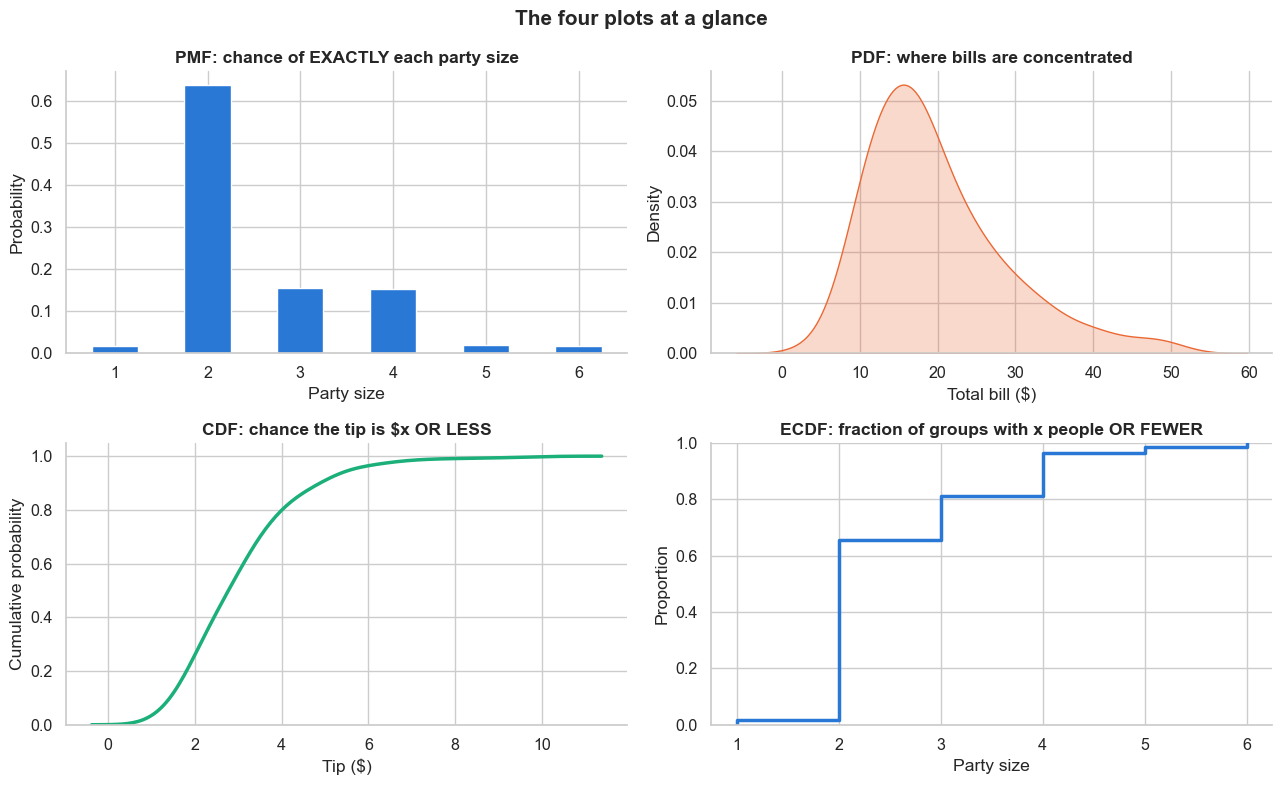

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# PMF
pmf = tips["size"].value_counts(normalize=True).sort_index()
ax[0, 0].bar(pmf.index, pmf.values, color=BLUE, width=0.5)
ax[0, 0].set(title="PMF: chance of EXACTLY each party size", xlabel="Party size", ylabel="Probability")

# PDF
sns.kdeplot(data=tips, x="total_bill", fill=True, color=ORANGE, ax=ax[0, 1])
ax[0, 1].set(title="PDF: where bills are concentrated", xlabel="Total bill ($)")

# CDF
sns.kdeplot(data=tips, x="tip", cumulative=True, color=GREEN, lw=2.5, ax=ax[1, 0])
ax[1, 0].set(title="CDF: chance the tip is $x OR LESS", xlabel="Tip ($)", ylabel="Cumulative probability")

# ECDF
sns.ecdfplot(data=tips, x="size", color=BLUE, lw=2.5, ax=ax[1, 1])
ax[1, 1].set(title="ECDF: fraction of groups with x people OR FEWER", xlabel="Party size")

for a in ax.flat:
    a.title.set_fontweight("bold")
plt.suptitle("The four plots at a glance", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

? size of a table is discrete
1. PMF
2. CDF


? Is Tip a continuous or discrete variable ?

It is a continuous variable

1. PDF
2. CDF

In [19]:
tips.head(5)

tips[tips['tip'] <= 4].shape[0]

203

In [20]:
203/244

0.8319672131147541

In [12]:
198/244

0.8114754098360656

In [10]:
P(X<=3) = 198/244 = 0.81

0.8114754098360656

### Step 3: Illustrated version, showing what the PDF captures

### What the PDF captures
- **Shape:** where values bunch up (the peak) and where they thin out (the tails).
- **Area = probability.** The shaded area between \$10 and \$20 is the chance a bill falls in that range.
- **Height is NOT a probability.** A density of 0.05 doesn't mean "5%". Only **areas** are probabilities.
- **Total area under the curve = 1** (100% of bills).
- **It's a smoothed estimate.** The curve's area (≈46%) is close to, but not exactly, the raw count (53%). Smoothing spreads the data out a little, and the curve even leaks slightly below \$0, which is impossible for a real bill. Good enough to see the shape, but count the raw data when you need an exact number.

### How to describe a PDF: use **S-C-S-O**
| Letter | Ask yourself | For `total_bill` |
|:---:|---|---|
| **S**hape | Symmetric? Skewed left or right? One peak or two? | **Right-skewed**, one peak |
| **C**enter | Where is the peak / median? | Peak ≈ **\$16**, median ≈ **\$17.80** |
| **S**pread | Where do most values lie? | Most bills between **\$10 and \$30** |
| **O**utliers | Any unusual values far away? | A few bills of **\$40–\$50** |

**Example answer:**
> The distribution of total bills is **right-skewed** with one peak around **\$16**. Most bills fall between **\$10 and \$30**, and about **half** are between \$10 and \$20. A small number of large bills (\$40–\$50) create a long right tail, which pulls the **mean (\$19.79) above the median (\$17.80)**.

<details>
<summary><b>Quick check (click for answers)</b></summary>

1. Is the curve's height at \$16 the probability of a \$16 bill? Answer: **No.** Height is density. For a continuous variable, the chance of *exactly* \$16.000… is essentially 0.
2. Why is the mean bigger than the median? Answer: The few large bills in the right tail pull the mean up. The median isn't affected much.
3. What is the total area under the curve? Answer: **1**
</details>

---
## 5. CDF: Cumulative Distribution Function (Continuous: `tip`)

### Problem statement
> **A new waiter is planning his budget.** He asks:
> *"What's the chance a table tips **\$3 or less**? What tip amount do **half** of tables stay under? And what's a 'great' tip, one that only the top 10% of tables beat?"*
>
> **Task:** Draw the **CDF** of `tip` and read all three answers directly from the graph.




There are two ways to read a CDF:
- **Across then up** (x to y): *"What's the chance of \$3 or less?"*
- **Up then across** (y to x): *"What tip do 50% stay under?"* This gives a **percentile**.

> **Why do the curve and the raw data differ slightly?** The smooth CDF is built from the smoothed PDF, so it gives **estimates** (0.57, \$2.77, \$4.89). Counting the raw data gives 0.60, \$2.90 and \$5.00. Both tell the same story. For exact figures from the data, use the **ECDF** (Section 6).

### What the CDF captures
- **Running total.** The height at any point x is the **fraction of values ≤ x**.
- **Always goes up** (or stays flat). It never goes down, and it runs from **0** on the left to **1** on the right.
- **Steep parts** are where many values are packed (here \$2–\$4). **Flat parts** are where values are rare.
- **Percentiles** (median, 90th, etc.) can be read directly: go **up** to the level, then **across** to the curve, then **down**.
- **"More than" questions:** P(tip > x) = **1 − CDF(x)**

### How to describe it (sentence template)
> *"About **___%** of values are at or below **___**. The median is about **___**. The curve rises steeply between **___** and **___**, so most values lie there. Only **___%** exceed **___**."*

**Example answer:**
> About **60%** of tips are **\$3 or less**, and the **median** tip is just under **\$3**. The curve climbs steeply between **\$2 and \$4**, so most tips fall in that range. Only about **10%** of tables tip more than **~\$5**, so anything above \$5 is a great tip.

<details>
<summary><b>Quick check (click for answers)</b></summary>

1. What's the chance a tip is **more than** \$3? Answer: 1 − 0.60 ≈ **0.40**
2. Where on the curve are tips most common, the steep part or the flat part? Answer: The **steep** part.
3. Can a CDF ever go down? Answer: **No.** A running total can only grow or stay the same.
</details>

---
## 6. ECDF: Empirical CDF (Discrete: `size`)

### Problem statement
> **The manager is buying new tables.** She asks:
> *"If I only buy tables that seat up to **2**, what fraction of groups can I seat? What about tables up to **4**? What size should my biggest table be to seat at least **95%** of groups?"*
>
> **Task:** Draw the **ECDF** of `size` and answer all three questions from the steps.

**"Empirical"** means *"built directly from the data we observed"*. There's no smoothing: each step is real data.

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3> The binomial distribution </h3>
</div>

### The story
FreshMart is launching a new mango juice. A staff member hands out free samples. From past promotions, the store knows that **1 in 5 people (20%) who try a sample go on to buy the product.** Today, **20 shoppers** try it.

The marketing manager asks: *"What's the chance we sell to **8 or more** of them? If that happens, the promotion counts as a hit."*

### The idea
Many situations are just a **yes/no question asked repeatedly**:
- Does this shopper buy? *(yes/no)*
- Does this email get opened? *(yes/no)*
- Is this light bulb faulty? *(yes/no)*
- Is this café table a smoker? *(yes/no)*

A single yes/no trial is called a **Bernoulli trial**. Count the "yeses" over *n* repeated trials and that count follows a **binomial distribution**.

**When to use it, the BINS checklist:**
- **B**inary: each trial has only two outcomes (success/failure)
- **I**ndependent: one trial doesn't affect another
- **N**umber of trials is fixed in advance (n)
- **S**ame probability of success every time (p)


### Relevance and significance
The binomial is the basic model for **conversion rates, defect rates, survey results, clinical trials and A/B tests.** Every "X out of N said yes" figure you'll ever see is binomial underneath.

### Why a data scientist needs this
- **A/B testing:** 12 of 100 visitors clicked the new button and 9 of 100 clicked the old one. Is that a real improvement or luck? The binomial tells you.
- **Quality control:** if 3 of 50 parts are faulty, is the machine broken?
- **Classification:** logistic regression, one of the most widely used ML models, predicts *p* in a Bernoulli trial.



## Understanding *n* and *k* in the Binomial Formula

$$P(X = k) = \binom{n}{k} p^k (1-p)^{n-k}$$

The binomial formula answers one question: **"If I repeat something *n* times, what's the chance I get exactly *k* successes?"**



### *n* = the total number of trials

This is how many times you repeat the experiment, and it's fixed before you start. Each trial has only two outcomes, "yes" (success) or "no" (failure).

- Flipping a coin 10 times → $n = 10$
- Surveying 20 customers → $n = 20$

### *k* = the number of successes you're asking about

This is the specific count of "yeses" whose probability you want. It can be any whole number from $0$ to $n$.

- "What's the chance of exactly 3 heads?" → $k = 3$
- "What's the chance that exactly 15 customers are satisfied?" → $k = 15$

That leaves $n - k$ as the number of failures ("nos").



### Worked Example

You flip a fair coin 5 times. What's the chance of getting **exactly 2 heads**?

| Symbol | Meaning | Value |
|---|---|---|
| $n$ | number of flips | 5 |
| $k$ | number of heads | 2 |
| $n - k$ | number of tails | 3 |
| $p$ | chance of heads on one flip | 0.5 |

**Step 1: Probability of one particular order (e.g., HHTTT)**

$$p^k (1-p)^{n-k} = (0.5)^2 \times (0.5)^3 = \frac{1}{32}$$

**Step 2: Count how many different orders give 2 heads**

$$\binom{5}{2} = \frac{5!}{2!\,3!} = 10$$

(HHTTT, HTHTT, HTTHT, HTTTH, THHTT, THTHT, THTTH, TTHHT, TTHTH, TTTHH)

**Step 3: Multiply**

$$P(X = 2) = 10 \times \frac{1}{32} = 0.3125 \approx 31\%$$



**Easy way to remember:** *n* is how many times you try, and *k* is how many times you want it to work.



<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3> The normal distribution and the bell curve </h3>
</div>

### The story
In the 1870s, a scientist named **Francis Galton** built a board with rows of pins. Balls dropped from the top bounce left or right at each pin *at random*. You can't predict where any single ball will land. But after hundreds of balls, the pile at the bottom always forms the same shape: **a bell.**

### The idea
The **normal distribution** is a smooth, symmetric, bell-shaped curve. It's completely described by just two numbers:
- **μ (mean):** where the centre of the bell is
- **σ (standard deviation):** how wide the bell is

### Why does it show up so often in the real world?
1. Human and Animal Heights: Most adults cluster around an average height, with very short or very tall individuals becoming increasingly rare.
2. Birth Weights of Newborns: Infant birth weights form a classic bell curve, where the vast majority fall into a healthy middle range and extreme highs or lows are uncommon.
3. Leaf Sizes and Plant Characteristics: The length, surface area, or number of seeds on a specific plant species generally vary symmetrically around a standard mean.
4. Measurement and Observation Errors: Physical measurements of natural items, such as the diameter of raindrops, animal wingspans, or pebble sizes—naturally scatter around a true value due to minor random measurement variations.
5. physiological Traits: Resting heart rates, blood pressure levels in a healthy baseline population, and even intelligence quotient (IQ) scores closely mimic a normal curve.




### Symmetry and spread in machine learning
- **Standardisation:** most ML pipelines rescale features to mean 0 and SD 1 (`StandardScaler`) so that big-number features like salary don't swamp small-number ones like age.
- **Model assumptions:** linear regression assumes the prediction errors are normal and symmetric around 0.
- **Anomaly detection:** values far out in the tails of a bell curve get flagged as unusual (fraud, faulty sensors).

### Why a data scientist needs this
Confidence intervals, margins of error in polls ("±3%"), hypothesis tests and quality control limits are all built on the normal curve.

In [3]:
# Galton board simulation: 10,000 balls, 12 rows of pins, each bounce is left (0) or right (1)
balls, rows = 10_000, 12
slots = rng.integers(0, 2, size=(balls, rows)).sum(axis=1)   # final slot = number of 'rights'

counts = np.bincount(slots, minlength=rows + 1) / balls
x = np.arange(rows + 1)
mu, sigma = rows * 0.5, np.sqrt(rows * 0.25)
xs = np.linspace(0, rows, 300)

fig, ax = plt.subplots()
ax.bar(x, counts, color=BLUE, width=0.85, label="10,000 simulated balls")
ax.plot(xs, stats.norm.pdf(xs, mu, sigma), color=ORANGE, lw=2.5, label="normal curve")
ax.set_xlabel("Slot where the ball lands"); ax.set_ylabel("Fraction of balls")
ax.set_title("Galton board: random bounces pile up into a bell shape")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

NameError: name 'rng' is not defined

<div style="background-color: maroon; color: white; padding: 10px; border-radius: 5px;">
    <h3> Properties of the Normal distribution  </h3>
</div>

## Symmetry, standard deviation, z-scores

### (a) Symmetry
The normal curve is a mirror image around its mean. That means:
- **mean = median = mode**, all at the centre,
- 50% of values are below the mean and 50% are above,
- the chance of being 5 above the mean is the same as the chance of being 5 below it.

### (b) Standard deviation: the "typical distance from the mean"
The **standard deviation (SD, σ)** measures **spread**, meaning how far values typically are from the mean.
- Small SD: values huddle close to the mean, giving a tall, narrow bell. The process is consistent.
- Large SD: values are spread out, giving a short, wide bell. The process is unpredictable.

**The 68–95–99.7 rule (the "empirical rule"):**
- about **68%** of values fall within **1 SD** of the mean,
- about **95%** fall within **2 SD**,
- about **99.7%** fall within **3 SD**. Anything beyond 3 SD is very rare.

### (c) Z-scores: "how many standard deviations from the mean?"
$$z = \frac{x - \mu}{\sigma}$$
- z = 0: exactly average
- z = +2: two SDs **above** average (better than about 97.7% of the group)
- z = −1: one SD **below** average

A z-score turns *any* normal distribution into the **standard normal** (mean 0, SD 1). That's what makes different things comparable.

In [ ]:
# The 68-95-99.7 rule, drawn on the standard normal
z = np.linspace(-4, 4, 600)
fig, ax = plt.subplots()
ax.plot(z, stats.norm.pdf(z), color=INK, lw=2)
for k_, c, a in [(3, BLUE, 0.15), (2, BLUE, 0.3), (1, BLUE, 0.55)]:
    m = (z >= -k_) & (z <= k_)
    ax.fill_between(z[m], stats.norm.pdf(z[m]), color=c, alpha=a)
for k_, y in [(1, 0.2), (2, 0.08), (3, 0.025)]:
    pct = (stats.norm.cdf(k_) - stats.norm.cdf(-k_)) * 100
    ax.annotate("", xy=(-k_, y), xytext=(k_, y), arrowprops=dict(arrowstyle="<->", color=INK))
    ax.text(0, y + 0.008, f"{pct:.1f}% within ±{k_} SD", ha="center", color=INK,
            bbox=dict(facecolor="#fcfcfb", edgecolor="none", pad=1))
ax.set_xticks(range(-3, 4)); ax.set_xticklabels(["-3σ", "-2σ", "-1σ", "μ", "+1σ", "+2σ", "+3σ"])
ax.set_ylabel("Density"); ax.set_title("The 68–95–99.7 rule: the curve is symmetric around the mean")
plt.tight_layout(); plt.show()

<div style="color:#004d99;"><h3> Variance </h3></div>

**Variance** measures how much the values **wobble around the mean**.

How to build it:
1. Find the mean.
2. For each value, find its **distance from the mean** (its *deviation*).
3. **Square** each distance. This makes every distance positive, and it makes big distances count much more.
4. Average the squares. For a sample we divide by $n - 1$ instead of $n$; this small correction gives a fairer estimate.

$$s^2 = \frac{\sum (x - \bar{x})^2}{n - 1}$$

**Small variance** → values huddle close to the mean (predictable). **Big variance** → values are scattered (unpredictable).

**One annoyance:** the units get squared (minutes² or £²!). That's why we usually take the square root → the **standard deviation** (next topic).

<div style="color:#004d99;"><h3> Calculate the variance with a pen and a paper </h3></div>

## Calculating Variance with Pen and Paper

**Numbers:** 12, 8, 10, 14, 9, 84, 10  (n = 7)

**Step 1: Find the mean**

$$
\bar{x} = \frac{12 + 8 + 10 + 14 + 9 + 84 + 10}{7} = \frac{147}{7} = 21
$$

**Step 2: Make a table of distances from the mean, and square them**

| Value $x$ | Distance from mean $(x - 21)$ | Squared distance |
|---|---|---|
| 12 | −9 | 81 |
| 8 | −13 | 169 |
| 10 | −11 | 121 |
| 14 | −7 | 49 |
| 9 | −12 | 144 |
| 84 | +63 | 3969 |
| 10 | −11 | 121 |
| | **Sum = 0** (always!) | **Sum = 4654** |

**Step 3: Divide the sum of squares by n − 1**

$$
s^2 = \frac{4654}{7 - 1} = \frac{4654}{6} = 775.67
$$



**Step 4 (optional): Standard deviation**

$$
s = \sqrt{775.67} \approx 27.85
$$

**What stands out:** the value 84 alone contributes 3,969 of the 4,654. Squaring makes far-away values **very** loud.

**Without the 84** (8, 9, 10, 10, 12, 14, mean 10.5): the squared distances are 6.25, 2.25, 0.25, 0.25, 2.25 and 12.25, which sum to 23.5, so $s^2 = 23.5 / 5 = 4.7$.

> One outlier takes the variance from **4.7 to 775.67**.

<div style="color:#004d99;"><h3> An example of why I would like to understand the variance of a given distribution </h3></div>



Application of Variance in data science and machine learning

1. **Comparing models**: Two models both average 90% accuracy across test runs. One scores 89–91% every time. The other jumps between 80% and 99%. You deploy the steady one.
2. **Business planning**: Two stores both average $10,000 in daily sales. The one with high variance needs extra stock and staff to handle unpredictable busy days.
3. **Investing**: Two stocks average the same return. The one with higher variance is riskier.
4. **Feature selection**: A feature with almost zero variance (e.g., every customer has the same value) can't help a model tell people apart, so it's usually dropped.

Summary: The average tells you what usually happens. The variance tells you how much you can rely on it.

<div style="background:	#001a33; color:#FFF; padding:15px; border-radius:5px;">

</div>

<div style="color:#004d99;"><h3> Standard Deviation </h3></div>

The **standard deviation** (SD, written $s$ or $\sigma$) is simply the **square root of the variance**:

$$s = \sqrt{\text{variance}}$$

Taking the square root brings the units back to minutes (or £), so it's easy to understand: *"waits are typically about s minutes away from the average."*

**The 68 – 95 – 99.7 rule** (for bell-shaped data):
- about **68 %** of values are within **1 SD** of the mean,
- about **95 %** within **2 SD**,
- about **99.7 %** within **3 SD**.

A value more than 3 SD from the mean is **very** unusual. The **z-score** $z = \dfrac{x - \text{mean}}{\text{SD}}$ tells you how many SDs away a value is.

<div style="color:#004d99;"><h3> Where is the standard deviation used ? </h3></div>

1. **Preparing data for AI (standardising):** turn every column into z-scores so that big numbers (like salary) don't overpower small ones (like age).
2. **Anomaly alarms:** flag values more than 3 SD from normal (e.g. an unusual heart rate on a smartwatch).
3. **Error bars** on charts and **margins of error** in opinion polls come from the SD.
4. **Manufacturing:** "Six Sigma" quality is named after the SD ($\sigma$).

<div style="color:#004d99;"><h3> Calculate the standard deviation with a pen and a paper </h3></div>

From B3: variance $= 775.67$ → $s = \sqrt{775.67} = \mathbf{£27.85}$

Without the $84: $s = \sqrt{4.7} = £2.17$.

**How unusual was the £84 shop?** Using a "normal hour" (mean £10.50, SD £2.17):

$$z = \frac{84 - 10.5}{2.17} = 33.9$$

Nearly **34 standard deviations** away: definitely not a typical top-up shop!



<div style="color:#004d99;"><h3> An example of why I would like to understand the standard deviation of a given distribution </h3></div>

## Why Calculate the Standard Deviation?

Variance tells you *how much* things vary, but it's measured in **squared units** ("minutes²"), which no one can picture. Standard deviation is the square root of variance, so it's back in the **original units** ("minutes"). That makes it a number you can use directly.

$$
\sigma = \sqrt{\text{Variance}}
$$

### Example: a pizza delivery promise

A pizza shop records its delivery times:

- **Average:** 30 minutes
- **Variance:** 25 minutes² (what does that even mean?)
- **Standard deviation:** $\sqrt{25}$ = **5 minutes**

Now the owner can reason in plain terms. For roughly bell-shaped data:

| Range | Share of deliveries |
|---|---|
| Average ± 1 SD: 25–35 min | about 68% |
| Average ± 2 SD: 20–40 min | about 95% |
| Average ± 3 SD: 15–45 min | about 99.7% |

So the owner can safely advertise **"Delivered in 40 minutes or it's free!"**, because only about 2–3% of orders will run past 40 minutes. The variance couldn't have told them that directly; the standard deviation does.

### Same idea in data science and machine learning

- **Feature scaling (standardization):** Age ranges from 20–60 and salary from 20,000–200,000. Without scaling, many models treat salary as more important just because its numbers are bigger. Rescaling each feature as $z = \frac{x - \mu}{\sigma}$ puts every feature on the same footing.
- **Outlier detection:** A transaction more than 3 SDs from a customer's usual spending gets flagged as possible fraud.
- **Reporting model results:** "Accuracy is 91% ± 1.5% across 5 cross-validation folds" shows whether the model is stable or just got lucky on one split.
- **Quality and monitoring:** If a server's response time is usually 200 ms ± 20 ms, an alert fires when it goes beyond 260 ms (3 SDs).

### Variance vs. standard deviation

| | Variance | Standard deviation |
|---|---|---|
| Units | Squared (min², \$²) | Same as the data (min, \$) |
| Easy to interpret? | No | Yes |
| Typically used for | Math and theory | Reporting, thresholds, scaling |

> **One-line summary:** Variance tells you that things are spread out. Standard deviation tells you **how far, in units you can use**.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>From probability to sampling: learning about everyone by looking at a few</h3>
</div>

### The story so far
Everything we've done so far used the waiter's notebook of **244 tables**. We counted, we computed probabilities, we drew distributions. But here's a question nobody has asked yet:

> *"Is the waiter's notebook the whole story, or just a slice of it?"*

The restaurant has served thousands of tables over the years. The waiter wrote down 244 of them, over a few months. So when we say "P(smoker) = 0.38", we really mean: **in this slice**, 38% of tables were smokers. Would a different slice say the same?

That's the big question for the rest of today: **how can we learn about everyone when we can only look at some of them?** People answer it every day, in every field:

| Where | What they wanted to know about **everyone** | What they actually looked at |
|---|---|---|
 **Vaccine trials** | Does the vaccine work for everyone? | The Pfizer COVID-19 trial tested about **43,000** volunteers. Its results guided decisions for billions of people. |

> **The soup analogy.** To check whether a big pot of soup needs salt, you don't drink the whole pot. You taste **one spoonful**. But you **stir first**. The pot is the **population**, the spoonful is the **sample**, and stirring is **random sampling**. Sections 1 to 4 are about those three things.

**Our flow of thought for the next four sections:**

| Step | The question | The idea |
|---|---|---|
| 1 | *Who* do we want to know about, and who can we actually look at? | **Population vs sample** |
| 2 | *How* should we pick who to look at? | **Sampling methods** |
| 3 | If we looked at a different group, *how much would our answer change?* | **Sampling distribution and standard error** |
| 4 | Why does that change always follow a bell curve? | **The Central Limit Theorem** |

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>1. Population vs sample</h3>
</div>

### The story
The restaurant owner wants to set next month's prices. She asks one question:

> *"What's the average bill per table?"*

Every receipt the waiter handled is in the office: **all 244 of them**. But each one is a crumpled bit of paper, and she has a restaurant to run. She has time to read only **30 receipts**. Can 30 receipts tell her about all 244?

### The idea
- The **population** is **everyone (or everything) we want to know about**. Here: all 244 tables in the waiter's records.
- A **sample** is **the part we actually look at**. Here: the 30 receipts she reads.
- A number that describes the **population** is called a **parameter**. It's fixed, but usually *unknown*.
- A number that describes the **sample** is called a **statistic**. We can calculate it, but it *changes* from sample to sample.

We use the **statistic** to **estimate** the **parameter**.

| | **Population** | **Sample** |
|---|---|---|
| What it is | Everyone we care about | The part we actually measure |
| Size | **N** (here 244) | **n** (here 30) |
| Mean | **μ** ("mu"), a **parameter** | **x̄** ("x-bar"), a **statistic** |
| Standard deviation | **σ** ("sigma") | **s** |
| Proportion (e.g. share of smokers) | **p** | **p̂** ("p-hat") |
| Do we know it? | Almost never | Always, because we measured it |
| Does it change? | No, it's one fixed number | **Yes**: a different sample gives a different value |
| Cost to measure | High (time, money), sometimes impossible | Low |

**Memory trick:** **P**arameter goes with **P**opulation. **S**tatistic goes with **S**ample.

### Properties to remember
- **Population:** complete and fixed. Usually too big, too expensive or impossible to measure fully. Sometimes it doesn't even exist yet: "every table the restaurant will serve next year".
- **Sample:** a subset. Quick and cheap, **but it wobbles**: two different handfuls of 30 receipts give slightly different averages. That wobble is called **sampling variability** (Section 3).
- A **good sample is a mini-version of the population**, with the same mix of days, lunch and dinner, small and big tables. Whether that's true depends on *how* it was chosen (Section 2).

### "Population" depends on the question
The same data can be a population for one question and a sample for another:
- *"What was the average bill across the waiter's 244 tables?"* The 244 tables **are** the population. We can compute μ exactly.
- *"What's the average bill at this restaurant, ever?"* Then the 244 tables are just a **sample** of all the restaurant's tables, and 19.79 is an **estimate**.

So always ask first: **"What is the population I actually care about?"**

### Relevance and significance
Almost every number in the news is a **statistic reported as if it were a parameter**: "unemployment is 4.1%", "62% of teenagers use social media daily", "the average house price is £290,000". Someone measured a sample and reported it as if it described everyone.

### Practical applications
| Population (what we want to know about) | Sample (what we actually look at) |
|---|---|

| All of a supermarket's shoppers | The ones who answer a feedback survey |
| All the fish in a lake | The fish caught, measured and released |

### Why a data scientist needs this
**Every dataset you'll ever analyse is a sample**, even a huge one. Before drawing any conclusion, ask: *"What population is this a sample of, and does it fairly represent that population?"*

### Real-world problem

> **Problem.** The owner reads **30 randomly chosen receipts** out of the 244.
> 1. Estimate the average bill (x̄) and the share of smoking tables (p̂) from her 30 receipts.
> 2. This is a classroom, so we *can* also compute the true values for all 244 tables (μ and p). How close did 30 receipts get?

In [ ]:
N = len(tips)            # population size
n_owner = 30             # sample size

# The owner's random sample of 30 receipts


In [ ]:
# Sample Statistics: what the owner actually knows




In [ ]:
# Parameters: normally unknown, but here we can peek at all 244 tables



In [ ]:
# Comparing the Sample and the Population



**A note on `std()`:** for a **sample**, pandas divides by **n − 1** (`ddof=1`, the default). For the **population** we tell it to divide by **N** (`ddof=0`). Dividing by n − 1 slightly corrects for the fact that a sample tends to *underestimate* the spread. You don't need to memorise this. Just know why the two are calculated slightly differently.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>2. Sampling methods: probability and non-probability</h3>
</div>

### The story
The owner is busy, so three people offer to pick the 30 receipts for her:

- **The manager** says: *"I only work weekend dinners, so I'll grab 30 receipts from my shifts. It's easy."*
- **The marketing assistant** says: *"Let's leave comment cards on the tables, and use the receipts of whoever fills one in."*
- **The data scientist** says: *"Number all 244 receipts. Let the computer pick 30 numbers completely at random. Read exactly those."*

All three will come back with an average. **Only one can be trusted.** Which one, and why?

### The idea
**How you choose the sample matters more than how big it is.** 

There are two families of sampling methods.

**Probability sampling:** every member of the population has a **known, non-zero chance** of being picked, and **chance, not a person, does the picking**.

| Method | How it works | Restaurant example | Good for |
|---|---|---|---|
| **Simple random** | Everyone has the same chance, like pulling names from a hat | Computer picks 30 of the 244 receipt numbers | The gold standard, when you have a full list |
| **Systematic** | Pick a random starting point, then every *k*-th one | Random start, then every 8th receipt in the book | Quick when working down a list, a queue or a production line |
| **Stratified** | Split into groups (**strata**) first, then pick randomly *inside every group*, in the right proportions | Random receipts from **each day** (Thur, Fri, Sat, Sun) in proportion to how busy each day is | Making sure every group is represented. Often a little more precise. |
| **Cluster** | Split into groups (**clusters**), pick a few *whole groups* at random, and look at everything in them | Pick 2 whole **shifts** at random and read every receipt from those shifts | Cheap when items come in natural bundles. But less precise if the groups differ. |

**Non-probability sampling:** people are picked because they're **easy to reach, volunteered, or were hand-picked by someone**. Some members have **no chance** of being chosen, so the sample can be unrepresentative in a consistent direction. This is called **bias**.

| Method | How it works | Restaurant example | The danger |
|---|---|---|---|
| **Convenience** | Whoever is easiest to reach | The manager's weekend-dinner receipts | Weekend dinners aren't typical of the whole week |
| **Voluntary response** | People choose themselves | Whoever fills in a comment card | Big groups have more people, so more chance someone fills one in |
| **Quota** | Fill a set number per group, but **choose freely** within it | "15 tables where a man paid, 15 where a woman paid", picked from the ones the waiter remembers | Right mix of groups, but people remember the big, expensive tables |
| **Judgement (purposive)** | An expert hand-picks "typical" cases | The waiter picks the receipts he thinks are "normal" | Only as good as the expert's guess |
| **Snowball** | Each person recruits the next | Regulars ask their friends to fill in a survey | Friends tend to be alike |

> **Stratified vs cluster** is the pair students mix up most. **Stratified:** take *some* from **every** group. **Cluster:** take *all* from **some** groups.

### Relevance and significance
- **Bias does not shrink when the sample gets bigger.** A biased method with 2.4 million people is still biased, just *confidently* wrong. A random sample of 1,000 beats it.
- Non-probability samples aren't useless. They're fine for early exploration, focus groups and pilot tests. You just can't use them to make precise claims about the whole population.

### Practical applications
- **Election polls:** stratified by region, age and gender, so every group is properly represented.
- **Factory quality checks:** systematic, testing every 100th item off the production line.
- **National health surveys:** cluster sampling. Pick random towns, then households within them, because visiting random homes across a whole country is too expensive.
- **Online reviews:** voluntary response. That's why reviews bunch up at 5 stars and 1 star: people with strong feelings are the ones who reply.

### Why a data scientist needs this
Most company data is **not** a random sample. It's app users, people who clicked, customers who complained. Knowing *how* data was collected tells you which population it really represents. A model trained on a biased sample makes biased predictions.

### Real-world problem: whose 30 receipts should the owner trust?

> **Problem.** Use each of the 7 methods below to pick about 30 of the 244 receipts, and estimate the average bill.
> One try could be lucky or unlucky, so **repeat each method 1,000 times** and see where its estimates land compared with the true μ.
>
> - A method whose estimates **centre on μ** is **unbiased**.
> - A method whose estimates are **tightly bunched** is **precise**.
> - We want both.

First we need one extra column. The receipts are in the order they were written, so every time the day or the lunch/dinner time changes, a new **shift** begins. Shifts are our **clusters**.

In [ ]:
day_time = tips["day"].astype(str) + " " + tips["time"].astype(str)
tips["shift"] = (day_time != day_time.shift()).cumsum()        # 1, 2, 3, ... each time the shift changes
print(f"The 244 receipts come from {tips['shift'].nunique()} shifts.")
tips.groupby("shift").agg(day=("day", "first"), time=("time", "first"), tables=("total_bill", "size")).T

In [ ]:
n_pick = 30
day_share = tips["day"].value_counts(normalize=True)

# ---------- probability methods ----------
def simple_random():
    return tips.sample(n_pick, random_state=rng.integers(1e9))

def systematic():
    k = len(tips) // n_pick                     # every k-th receipt (k = 8)
    start = rng.integers(k)                     # random starting point
    return tips.iloc[start::k].head(n_pick)

def stratified():
    # random receipts from EVERY day, in proportion to how busy each day is
    parts = [tips[tips["day"] == d].sample(round(share * n_pick), random_state=rng.integers(1e9))
             for d, share in day_share.items()]
    return pd.concat(parts)

def cluster():
    # pick 2 WHOLE shifts at random and read every receipt from them
    chosen = rng.choice(tips["shift"].unique(), size=2, replace=False)
    return tips[tips["shift"].isin(chosen)]

# ---------- non-probability methods ----------
def convenience():
    # the manager: only the weekend dinners he works
    weekend = tips[tips["day"].isin(["Sat", "Sun"])]
    return weekend.sample(n_pick, random_state=rng.integers(1e9))

def voluntary():
    # comment cards: each diner might fill one in, so bigger groups are more likely to reply
    return tips.sample(n_pick, weights=tips["size"], random_state=rng.integers(1e9))

def quota():
    # 15 tables where a man paid, 15 where a woman paid, but chosen from the ones the waiter
    # remembers: bigger bills are more memorable
    parts = [tips[tips["sex"] == g].sample(n_pick // 2, weights=tips.loc[tips["sex"] == g, "total_bill"],
                                           random_state=rng.integers(1e9))
             for g in ["Male", "Female"]]
    return pd.concat(parts)

methods = {"Simple random": simple_random, "Systematic": systematic, "Stratified": stratified,
           "Cluster (2 shifts)": cluster, "Convenience": convenience,
           "Voluntary response": voluntary, "Quota": quota}
probability_methods = ["Simple random", "Systematic", "Stratified", "Cluster (2 shifts)"]

In [ ]:
# One try with each method
print(f"True average bill μ = ${mu:.2f}\n")
print(f"{'Method':20}{'Family':>17}{'tables':>8}{'x̄ ($)':>9}{'Error ($)':>11}")
for name, pick in methods.items():
    chosen = pick()
    family = "probability" if name in probability_methods else "non-probability"
    print(f"{name:20}{family:>17}{len(chosen):>8}{chosen['total_bill'].mean():>9.2f}"
          f"{chosen['total_bill'].mean() - mu:>+11.2f}")

In [ ]:
# Repeat every method 1,000 times: where do its estimates land?
REPEATS = 1_000
results = {name: np.array([pick()["total_bill"].mean() for _ in range(REPEATS)])
           for name, pick in methods.items()}

summary = pd.DataFrame({
    "average estimate ($)": {k: v.mean() for k, v in results.items()},
    "bias ($)":             {k: v.mean() - mu for k, v in results.items()},
    "spread ($)":           {k: v.std() for k, v in results.items()},
}).round(2)
summary

### Can we draw it? Yes: where each method's 1,000 tries land
Each row shows the 1,000 estimates one method produced. The dashed line is the **true** average μ. Good methods sit **on** the line and are **narrow**.

In [ ]:
names  = list(results)[::-1]                 # keep the table's order, top to bottom
colors = [BLUE if m in probability_methods else ORANGE for m in names]

fig, ax = plt.subplots(figsize=(9, 5))
bp = ax.boxplot([results[m] for m in names], vert=False, widths=0.55, patch_artist=True,
                showfliers=False, medianprops=dict(color=INK))
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c); patch.set_alpha(0.55); patch.set_edgecolor(c)
ax.set_yticks(range(1, len(names) + 1)); ax.set_yticklabels(names)
ax.axvline(mu, color=INK, ls="--", lw=1.5)
ax.text(mu + 0.15, 0.35, f"true μ = ${mu:.2f}", color=INK)
ax.set_ylim(0.2, len(names) + 0.5)
ax.set_xlabel("Estimated average bill ($), 1,000 tries per method")
ax.set_title("Blue (probability) methods centre on the truth; orange ones overshoot")
plt.tight_layout(); plt.show()

**Things to note:**
- **Simple random, systematic and stratified** all centre on the true μ: they're **unbiased**, with similar spread. Stratifying by day helps only a little here, because bills vary much more *within* a day than *between* days.
- **Cluster** is also centred on μ, but it's the **widest**. Two shifts might be two quiet Thursday lunches or two busy Saturday dinners, so the estimate swings a lot. Cluster sampling is cheap, but imprecise.
- **Convenience, voluntary response and quota** are all **shifted to the right**. Any single try might land near μ by luck, but **on average** they overestimate the bill, and repeating them just repeats the same mistake. Quota is the worst here, at about \$3 too high. This is exactly what went wrong for the *Literary Digest*.
- **Quota** gets the male/female mix exactly right and *still* overshoots, because *within* each group it favours memorable, expensive tables.

**Bias vs noise, the dartboard picture:**
- **Noise (random error):** darts scattered *around* the bullseye. A bigger sample reduces it.
- **Bias:** darts bunched together in the *wrong place*. A bigger sample does **not** fix it. Only a better method does.

**Application:** before trusting any survey or dataset, ask one question: **"How were these chosen?"** If the answer is "whoever replied" or "whoever was easy to reach", be suspicious, however big the sample is.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>3. Sampling distribution of the mean and standard error</h3>
</div>

## Standard Error

**Standard error tells you how much your average would change if you took a different sample.** In other words, it measures how much you can trust your average.

### A simple example

You want to know the average height of adults in your city. You can't measure everyone, so you measure 50 random people and get **5 ft 7 in**.

If a friend measured a *different* 50 people, they might get 5 ft 6.5 in, and another friend might get 5 ft 7.5 in. Each sample gives a slightly different average.

**The standard error is the typical amount these averages differ from each other**, and from the true city-wide average.

- **Small standard error:** everyone's averages land close together, so your number is reliable.
- **Large standard error:** the averages bounce around a lot, so your number is shaky.

### Standard deviation vs. standard error

People often confuse these two.

| | What it measures | Height example |
|---|---|---|
| **Standard deviation** | How much **individual people** differ from each other | People range from 5 ft to 6 ft 4 in, so the spread is large |
| **Standard error** | How much **the average** would differ between samples | The average of 50 people barely moves, so the spread is small |

Individuals vary a lot, but averages of groups vary much less, because tall and short people cancel each other out.

### What makes it smaller?

$$
\text{Standard Error} = \frac{\sigma}{\sqrt{n}}
$$

where $\sigma$ is the standard deviation and $n$ is the sample size.

- **More data gives a smaller standard error.** Measuring 500 people instead of 50 makes your average much more trustworthy.
- But it grows slowly: to **halve** the standard error, you need **four times** as much data.

### Where you see it in real life

- **Election polls:** "52% ± 3%". That ± is based on the standard error.
- **Model accuracy:** "92% ± 2.4%". It tells you whether one model is truly better than another or just got lucky.
- **A/B tests:** It tells you whether a difference between two versions is real or just random noise.


<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>4. The Central Limit Theorem</h3>
</div>

# Central Limit Theorem (CLT)

When we want to study a large population, measuring every member is usually impractical. Instead, we draw **samples** from the population and use them to draw conclusions about it.

The **Central Limit Theorem** states that:

> The mean of samples (size ≥ 30) follows a **normal distribution**, no matter what the distribution of the underlying population is.

### Key properties
- The mean of the sampling distribution is approximately equal to the **population mean** (μ).
- The spread of the sample means (standard error) is **σ / √n**, so it shrinks as the sample size *n* grows.
- Larger samples capture more of the population's diversity, so the sample mean becomes a more accurate estimate.

## Step 1: Create a non-normal population

To show that the CLT works regardless of the population's shape, we generate a population from an **exponential distribution**, which is strongly right-skewed and clearly *not* normal.

In [ ]:
# create an exponential distribution with mean 1 and standard deviation 1; with population size 100,000

population = np.random.exponential(scale=1.0, size=100000)

print(f"Population mean: {population.mean():.4f}")
print(f"Population std : {population.std():.4f}")

plt.figure(figsize=(8, 4))
sns.histplot(population, bins=100, kde=True, color="steelblue")
plt.title("Population Distribution (Exponential)")
plt.xlabel("Value")
plt.show()

## Step 2: Draw many samples and compute their means

We take **1,000 random samples**, each of **size 30**, and record the mean of each sample. The resulting collection of means is called the **sampling distribution of the mean**.

In [ ]:
n_samples = 1000
sample_size = 30


#
sample_means = [
    np.random.choice(population, size=sample_size, replace=True).mean()
    for i in range(n_samples)
]

plt.figure(figsize=(8, 4))
sns.histplot(sample_means, bins=40, kde=True, color="darkorange")
plt.axvline(population.mean(), color="red", linestyle="--", label="Population mean")
plt.title(f"Distribution of {n_samples} Sample Means (n = {sample_size})")
plt.xlabel("Sample mean")
plt.legend()
plt.show()

In [ ]:
mu = population.mean()
sigma = population.std()

print(f"Mean of sample means      : {np.mean(sample_means):.4f}  (population mean = {mu:.4f})")
print(f"Std of sample means       : {np.std(sample_means):.4f}")
print(f"Theoretical std error σ/√n: {sigma / np.sqrt(sample_size):.4f}")

## Step 4: Effect of sample size, on why 30 matters

Next we repeat the experiment with different sample sizes. With **small samples** (e.g., 2 or 5), the distribution of means still looks skewed like the population. Around **n = 30 and above**, it closely resembles a **normal distribution** and gets narrower as *n* increases.

This makes n ≈ 30 a practical rule-of-thumb threshold for applying the CLT.

In [ ]:
sample_sizes = [2, 5, 10, 30, 50, 100]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, n in zip(axes.flat, sample_sizes):
    means = [np.random.choice(population, size=n).mean() for _ in range(n_samples)]
    sns.histplot(means, bins=40, kde=True, ax=ax, color="seagreen")
    ax.axvline(mu, color="red", linestyle="--")
    ax.set_title(f"Sample size n = {n}")
    ax.set_xlabel("Sample mean")

plt.suptitle("Sampling Distribution of the Mean for Different Sample Sizes", fontsize=14)
plt.tight_layout()
plt.show()

## Conclusion

- Even though the population is **exponential (skewed)**, the means of samples of size ≥ 30 are approximately **normally distributed**.
- The mean of the sample means is very close to the **population mean**.
- As the sample size increases, the sampling distribution becomes **narrower** (smaller standard error), so estimates become more accurate.
- This is why the CLT is fundamental to confidence intervals, hypothesis testing, and A/B testing in data science.

<div style="background-color: #0f1056; color: white; padding: 10px; border-radius: 5px;">
    <h3>Putting it all together</h3>
</div>

| Idea | One-line meaning | In our restaurant |
|---|---|---|
| **Population** | Everyone we want to know about. Its numbers (**parameters**: μ, σ, p) are fixed but usually unknown. | All 244 tables in the waiter's records |
| **Sample** | The part we actually measure. Its numbers (**statistics**: x̄, s, p̂) are known but wobble. | The owner's 30 receipts |
| **Sampling method** | *How* the sample is chosen. Random methods are unbiased; convenience and volunteer samples usually aren't. | Computer-picked receipts vs "my weekend shifts" |
| **Sampling distribution** | The pattern of x̄ from many repeated samples. | 10,000 simulated nights |
| **Standard error** | How much x̄ typically wobbles: **σ/√n**. Shrinks as samples get bigger, but slowly. | About \$1.60 for 30 tables |
| **Central Limit Theorem** | For large enough n, x̄ (and totals) are approximately normal, whatever the population's shape. | Skewed tips → bell-shaped nightly totals → a predictable Saturday |

**The flow of thought:**
we want a fact about the **population** → we can only afford a **sample** → we must pick it **randomly**, or it's biased → even a random sample **wobbles**, by one **standard error** → thanks to the **CLT**, that wobble follows a **bell curve** → so we can say *how sure* we are. (Next session: **confidence intervals** and **hypothesis tests**.)
